# **Aprendizaje Automático 1 - Trabajo Práctico 2**
## EDA - Predicción de lluvias en Australia

**Integrantes:** Alejandro Acosta, Diego Hauret, Gastón Rinaldi, Agustín Torres

Análisis exploratorio de datos previo a la construcción de un modelo de ...

**Indice:**
1. Carga y comprensión de los datos
2. Análisis de valores faltantes
3. Imputación de valores faltantes (ejemplo)
4. Análisis univariado (variable objetivo y predictoras)
5. Análisis bivariado (correlaciones y relación con MEDV)
6. Multicolinealidad entre predictoras
7. Detección de outliers
8. Conclusiones y próximos pasos


## Diccionario de variables

| Variable | Descripción |
| :--- | :--- |
| **Unnamed** | Índices |
| **Date** | Fecha |
| **Location** | Localidad de ubicación de la estación meteorológica |
| **MinTemp** | Temperatura mínima en °C |
| **MaxTemp** | Temperatura máxima en °C |
| **Rainfall** | Cantidad de lluvia registrada durante las últimas 24 horas (mm) |
| **Evaporation** | Evaporación aparente calculada (medida en mm) |
| **Sunshine** | Número de horas totales de sol brillante registradas a lo largo del día |
| **WindGustDir** | Dirección de la ráfaga de viento más fuerte |
| **WindGustSpeed** | Velocidad de la ráfaga de viento más fuerte |
| **WindDir9am** | Dirección del viento registrada a las 09:00 horas |
| **WindDir3pm** | Dirección del viento registrada a las 15:00 horas |
| **WindSpeed9am** | Velocidad del viento (en km/h). Promedio de los 10 minutos anteriores |
| **WindSpeed3pm** | Velocidad del viento (en km/h). Promedio de los 10 minutos anteriores |
| **Humidity9am** | Porcentaje de humedad relativa registrado a las 09:00 horas |
| **Humidity3pm** | Porcentaje de humedad relativa registrado a las 15:00 horas |
| **Pressure9am** | Presión atmosférica a las 09:00 horas (en hectopascales) |
| **Pressure3pm** | Presión atmosférica a las 15:00 horas (en hectopascales) |
| **Cloud9am** | Nubosidad a las 09:00 horas (0 indica cielo despejado y 8 nublado total) |
| **Cloud3pm** | Nubosidad a las 15:00 horas (0 indica cielo despejado y 8 nublado total) |
| **Temp9am** | Temperatura medida a las 09:00 horas en °C |
| **Temp3pm** | Temperatura medida a las 15:00 horas en °C |
| **RainToday** | Variable categórica binaria (Yes / No). Toma el valor Yes si la precipitación acumulada (Rainfall) en las últimas 24 horas hasta las 09:00 horas de día actual superó el 1.0 mm |
| **RainTomorrow** | Variable objetivo (target) a predecir (Yes / No). Indica si lloverá al día siguiente (las precipitaciones de mañana superarán el umbral de 1.0 mm) |

## 0. Carga de librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             matthews_corrcoef, cohen_kappa_score, log_loss, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             precision_recall_curve, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Carga y comprensión de los datos

In [2]:
df = pd.read_csv('weatherAUS_2026C2.csv')
print("Dimensiones:", df.shape)
df.head(10)


Dimensiones: (145412, 25)


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6000,22.5000,0.6000,NaN,NaN,W,45.0000,W,WNW,19.0000,25.0000,68.8000,23.8000,1008.1000,1007.2000,8.0000,NaN,16.8000,20.8000,No,No,0.0000
1,1,2008-12-02,Albury,7.3000,25.8000,0.0000,NaN,NaN,WNW,44.0000,NNW,WSW,4.0000,23.0000,40.1000,22.1000,1011.1000,1007.5000,NaN,NaN,18.3000,24.6000,No,No,0.0000
2,2,2008-12-03,Albury,13.2000,26.2000,0.0000,NaN,NaN,WSW,46.0000,W,WSW,20.0000,27.0000,36.2000,31.5000,1007.3000,1009.4000,NaN,2.0000,21.2000,23.4000,No,No,0.0000
3,3,2008-12-04,Albury,10.0000,28.8000,0.0000,NaN,NaN,NE,23.0000,SE,E,10.0000,10.0000,45.8000,18.5000,1017.6000,1012.4000,NaN,NaN,17.4000,26.3000,No,No,1.0000
4,4,2008-12-05,Albury,17.4000,32.4000,1.0000,NaN,NaN,W,41.0000,ENE,NW,6.0000,17.0000,83.5000,34.6000,1010.9000,1005.9000,7.0000,8.0000,17.9000,29.1000,No,No,0.2000
5,5,2008-12-06,Albury,14.5000,30.1000,0.2000,NaN,NaN,WNW,55.0000,W,W,19.0000,24.0000,56.6000,23.0000,1009.9000,1005.5000,NaN,NaN,20.9000,28.2000,No,No,0.0000
6,6,2008-12-07,Albury,15.1000,25.3000,0.0000,NaN,NaN,W,51.0000,SW,W,21.0000,24.0000,46.8000,20.3000,1009.3000,1008.5000,1.0000,NaN,18.3000,24.0000,No,No,0.0000
7,7,2008-12-08,Albury,8.1000,26.1000,0.0000,NaN,NaN,W,34.0000,SSE,W,5.0000,16.0000,46.8000,20.8000,1013.5000,1009.7000,NaN,NaN,17.1000,25.9000,No,No,0.0000
8,8,2008-12-09,Albury,9.5000,31.8000,0.0000,NaN,NaN,NNW,80.0000,SE,NW,6.0000,28.0000,42.1000,8.5000,1008.9000,1003.6000,NaN,NaN,18.0000,28.9000,No,Yes,1.4000
9,9,2008-12-10,Albury,13.4000,30.1000,1.4000,NaN,NaN,W,28.0000,S,SSE,14.0000,12.0000,57.6000,24.6000,1007.2000,1005.7000,NaN,NaN,18.9000,28.2000,Yes,No,0.0000


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

### Observaciones sobre las columnas del archivo


* Unnamed: 0: es un índice que no aporta información, entonces se elimina.
* RainfallTomorrow: es la **cantidad de lluvia (mm) de mañana**. Es una fuga de información (*data leakage*): RainTomorrow se define justamente como "mañana llovió ≥ 1 mm", por lo que esta columna casi determina el target. En un caso real **no la conoceríamos al momento de predecir**. Se elimina de los predictores.

Date no se usa como número, pero de ella sacamos el **mes** (la lluvia es estacional).

In [4]:
df = df.drop(columns=["Unnamed: 0"])
df["Date"] = pd.to_datetime(df["Date"])

num_cols = df.select_dtypes(include="number").columns.drop("RainfallTomorrow").tolist()
cat_cols = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]

print("Período:", df["Date"].min().date(), "->", df["Date"].max().date())
print("Ubicaciones de las estaciones:", df["Location"].nunique())
print("Filas duplicadas:", df.duplicated().sum())
print("\nVariables numéricas:", num_cols)
print("Variables categóricas:", cat_cols)

Período: 2007-11-01 -> 2017-06-24
Ubicaciones de las estaciones: 49
Filas duplicadas: 0

Variables numéricas: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Variables categóricas: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


### Variables numéricas: rango de variación y estadísticos

In [5]:
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["%nulos"] = (df[num_cols].isna().mean() * 100).round(1)
print('Estadísticos descriptivos:')
print('=' * 110)
desc.round(2)

Estadísticos descriptivos:


,count,mean,std,min,25%,50%,75%,max,skew,%nulos
MinTemp,143928.0000,12.2000,6.4200,-9.7000,7.6000,12.0000,16.9000,34.1000,0.0200,1.0000
MaxTemp,144159.0000,23.2200,7.1400,-5.1000,17.9000,22.6000,28.2000,49.1000,0.2200,0.9000
Rainfall,142152.0000,2.3600,8.4800,0.0000,0.0000,0.0000,0.8000,371.0000,9.8300,2.2000
Evaporation,82658.0000,5.4700,4.1900,0.0000,2.6000,4.8000,7.4000,145.0000,3.7600,43.2000
Sunshine,75616.0000,7.6100,3.7900,0.0000,4.8000,8.4000,10.6000,14.5000,-0.5000,48.0000
WindGustSpeed,135159.0000,40.0400,13.6500,6.0000,31.0000,38.0000,48.0000,135.0000,0.8700,7.1000
WindSpeed9am,143645.0000,14.0700,8.9400,0.0000,7.0000,13.0000,19.0000,130.0000,0.7900,1.2000
WindSpeed3pm,142351.0000,18.6600,8.8700,0.0000,12.0000,18.0000,24.0000,86.0000,0.6200,2.1000
Humidity9am,142759.0000,68.8600,19.0600,0.0000,57.0000,69.9000,83.1000,100.0000,-0.4900,1.8000
Humidity3pm,140907.0000,51.5300,20.8400,0.0000,36.6000,52.0000,65.7000,100.0000,0.0300,3.1000


### Variables categóricas: cardinalidad y categorías más frecuentes

In [6]:
for c in cat_cols + ["RainTomorrow"]:
    vc = df[c].value_counts(dropna=False)
    print(f"{c}: {df[c].nunique()} categorías | nulos: {df[c].isna().sum()} | top: {vc.head(5).to_dict()}")

Location: 49 categorías | nulos: 0 | top: {'Canberra': 3435, 'Sydney': 3343, 'Melbourne': 3192, 'Brisbane': 3192, 'Adelaide': 3192}
WindGustDir: 16 categorías | nulos: 10316 | top: {nan: 10316, 'W': 9910, 'SE': 9416, 'N': 9313, 'SSE': 9215}
WindDir9am: 16 categorías | nulos: 10562 | top: {'N': 11754, nan: 10562, 'SE': 9283, 'E': 9172, 'SSE': 9109}
WindDir3pm: 16 categorías | nulos: 4226 | top: {'SE': 10837, 'W': 10105, 'S': 9924, 'WSW': 9512, 'SSE': 9397}
RainToday: 2 categorías | nulos: 3260 | top: {'No': 110276, 'Yes': 31876, nan: 3260}
RainTomorrow: 2 categorías | nulos: 3259 | top: {'No': 110281, 'Yes': 31872, nan: 3259}


## 2. Análisis de valores faltantes


Revisamos cuántos nulos tiene cada columna y si hay algún patrón (filas con muchos nulos a la vez, o nulos concentrados).


In [7]:
faltante = df.isna().sum().sort_values(ascending=False)
faltante_pct = (faltante / len(df) * 100).round(2)
print("Cantidad de nulos por columna:")
pd.DataFrame({"nulos": faltante, "% nulos": faltante_pct})


Cantidad de nulos por columna:


,nulos,% nulos
Sunshine,69796,48.0000
Evaporation,62754,43.1600
Cloud3pm,59336,40.8100
Cloud9am,55870,38.4200
Pressure9am,15061,10.3600
Pressure3pm,15024,10.3300
WindDir9am,10562,7.2600
WindGustDir,10316,7.0900
WindGustSpeed,10253,7.0500
Humidity3pm,4505,3.1000


Se observa que las variables Sunshine, Evaporation, Cloud3pm y Cloud9am tienen más de 38% de valores faltantes. Esto tendremos que analizarlo más a fondo pues la lógica indica que a mayor nubosidad habrías más probabilidades de lluvias y no deberiamos descartarlos sin antes analizarlos.
La variable RainTomorrow, que es nuestra target, tiene 3259 valores faltantes. Esos registros los tenemos que eliminar.

In [8]:
nulos_por_fila = df.isna().sum(axis=1)
print("Cantidad de nulos por fila:\n",nulos_por_fila.value_counts().sort_index())


Cantidad de nulos por fila:
 0     56412
1     10764
2     18167
3      9920
4     28702
5      3774
6     10432
7      2087
8      1440
9       500
10      388
11      717
12      797
13      130
14      550
15       62
16       82
17      123
18       65
19       23
20       85
21       10
22      182
Name: count, dtype: int64


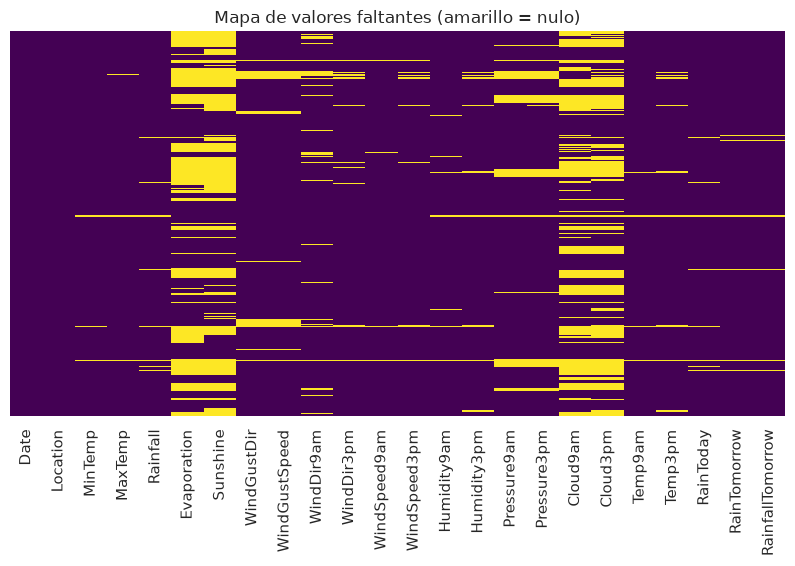

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False, ax=ax)
#cbar=False desactiva la barra lateral de medidas
#yticklabels=False oculta las etiquetas de valores del eje y
ax.set_title("Mapa de valores faltantes (amarillo = nulo)")
plt.show()


In [10]:
# ¿Los faltantes son aleatorios? Se ve si "estar faltante" depende de la estación meteorológica
faltante_alto = ["Evaporation", "Sunshine", "Cloud9am", "Cloud3pm"]
por_ubicacion = df.groupby("Location")[faltante_alto].agg(lambda s: s.isna().mean()).round(2)
print("Ubicaciones donde la variable NUNCA se mide (100% faltante):")
for c in faltante_alto:
    print(f"  {c}: {(por_ubicacion[c] == 1).sum()} de {len(por_ubicacion)} ubicaciones")
por_ubicacion.sort_values("Sunshine", ascending=False).head(10)

Ubicaciones donde la variable NUNCA se mide (100% faltante):
  Evaporation: 16 de 49 ubicaciones
  Sunshine: 19 de 49 ubicaciones
  Cloud9am: 12 de 49 ubicaciones
  Cloud3pm: 12 de 49 ubicaciones


,Evaporation,Sunshine,Cloud9am,Cloud3pm
Location,,,,
Albury,1.0000,1.0000,0.5800,0.5300
GoldCoast,1.0000,1.0000,1.0000,1.0000
BadgerysCreek,1.0000,1.0000,1.0000,1.0000
Bendigo,0.6100,1.0000,0.3200,0.2500
Ballarat,1.0000,1.0000,0.1800,0.3400
Katherine,0.0600,1.0000,0.0300,0.4600
Wollongong,1.0000,1.0000,0.5600,0.5300
Walpole,1.0000,1.0000,1.0000,1.0000
Uluru,1.0000,1.0000,0.7800,0.7400


## Decisión sobre faltantes

| Caso | Variables | Decisión | Justificación |
|---|---|---|---|
| **Target faltante** | `RainTomorrow` (~2 %) | **Se eliminan esas filas** | No se puede entrenar ni evaluar sin etiqueta. Imputar el target inventaría información. |
| **Muy altos (>30 %)** | `Evaporation`, `Sunshine`, `Cloud9am`, `Cloud3pm` | **Imputar con la mediana + agregar una variable indicadora "faltante"** | No se descartan porque `Sunshine` y `Cloud3pm` suelen estar entre los predictores más informativos. Además el faltante **no es aleatorio** (hay estaciones que directamente no miden estas variables), así que "no fue medida" es información en sí misma → la indicadora la captura. |
| **Moderados / bajos** | resto de numéricas | **Imputar con la mediana** (calculada solo con train) | La mediana es robusta a los outliers que vimos. |
| **Categóricas** | `WindGustDir`, `WindDir9am`, `WindDir3pm` | **Imputamos con forwardfill/backwardfill** | Imputa el dato faltante observando sus adyacentes, considerando la inercia de este tipo de variables físicas. |
| **`RainToday`** | ~2 % | **Se eliminan esas filas** | Es la misma situación que el target (si falta `Rainfall`, falta `RainToday`). |

> La imputación con la mediana se **ajusta únicamente con el conjunto de entrenamiento** para no filtrar información del test.

In [11]:
# Se eliminan las filas sin target o sin RainToday (se hace ANTES de dividir: no usa información de otras filas)
n0 = len(df)
df = df.dropna(subset=["RainTomorrow", "RainToday"]).copy()
print(f"Filas eliminadas: {n0 - len(df)} ({(n0 - len(df)) / n0:.2%}) | Filas restantes: {len(df)}")

Filas eliminadas: 4665 (3.21%) | Filas restantes: 140747


## 3. Análisis univariado



### 3.1 Variable objetivo: RainTomorrow

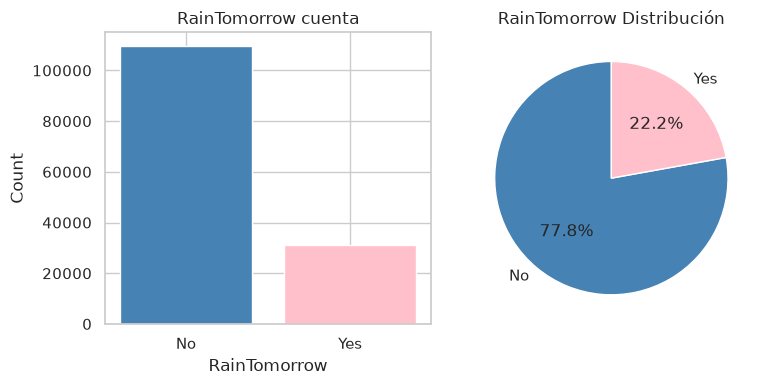

In [12]:
target_cant = df['RainTomorrow'].value_counts()
target_pct = df['RainTomorrow'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Diagrama de barras
axes[0].bar(target_cant.index, target_cant.values, color=['steelblue', 'pink'])
axes[0].set_title('RainTomorrow cuenta')
axes[0].set_xlabel('RainTomorrow')
axes[0].set_ylabel('Count')

# Diagrama de sectores
axes[1].pie(target_pct, labels=target_cant.index, autopct='%1.1f%%',
            colors=['steelblue', 'pink'], startangle=90)
axes[1].set_title('RainTomorrow Distribución')

plt.tight_layout()
plt.show()

El dataset **no está balanceado**: aproximadamente 78 % de los días *no* llueve y 22 % sí llueve.

**Es importante porque:**
* La **accuracy engaña**: un modelo "tonto" que siempre diga *"no lloverá"* acertaría ≈ 78 % sin haber aprendido nada. Por eso hay que mirar **precision, recall, F1, balanced accuracy, ROC-AUC**, etc.
* La regresión logística entrenada con la función de costo estándar tiende a **favorecer la clase mayoritaria** y deja la clase minoritaria (la de interés: "llueve") con **recall bajo**.
* Para la división train/test hay que **estratificar** (conservar la proporción de clases en cada subconjunto). Posibles remedios: class_weight="balanced", *over/undersampling* (p. ej. SMOTE) o ajustar el umbral. Acá probamos class_weight.

### 3.2 Distribución de las predictoras

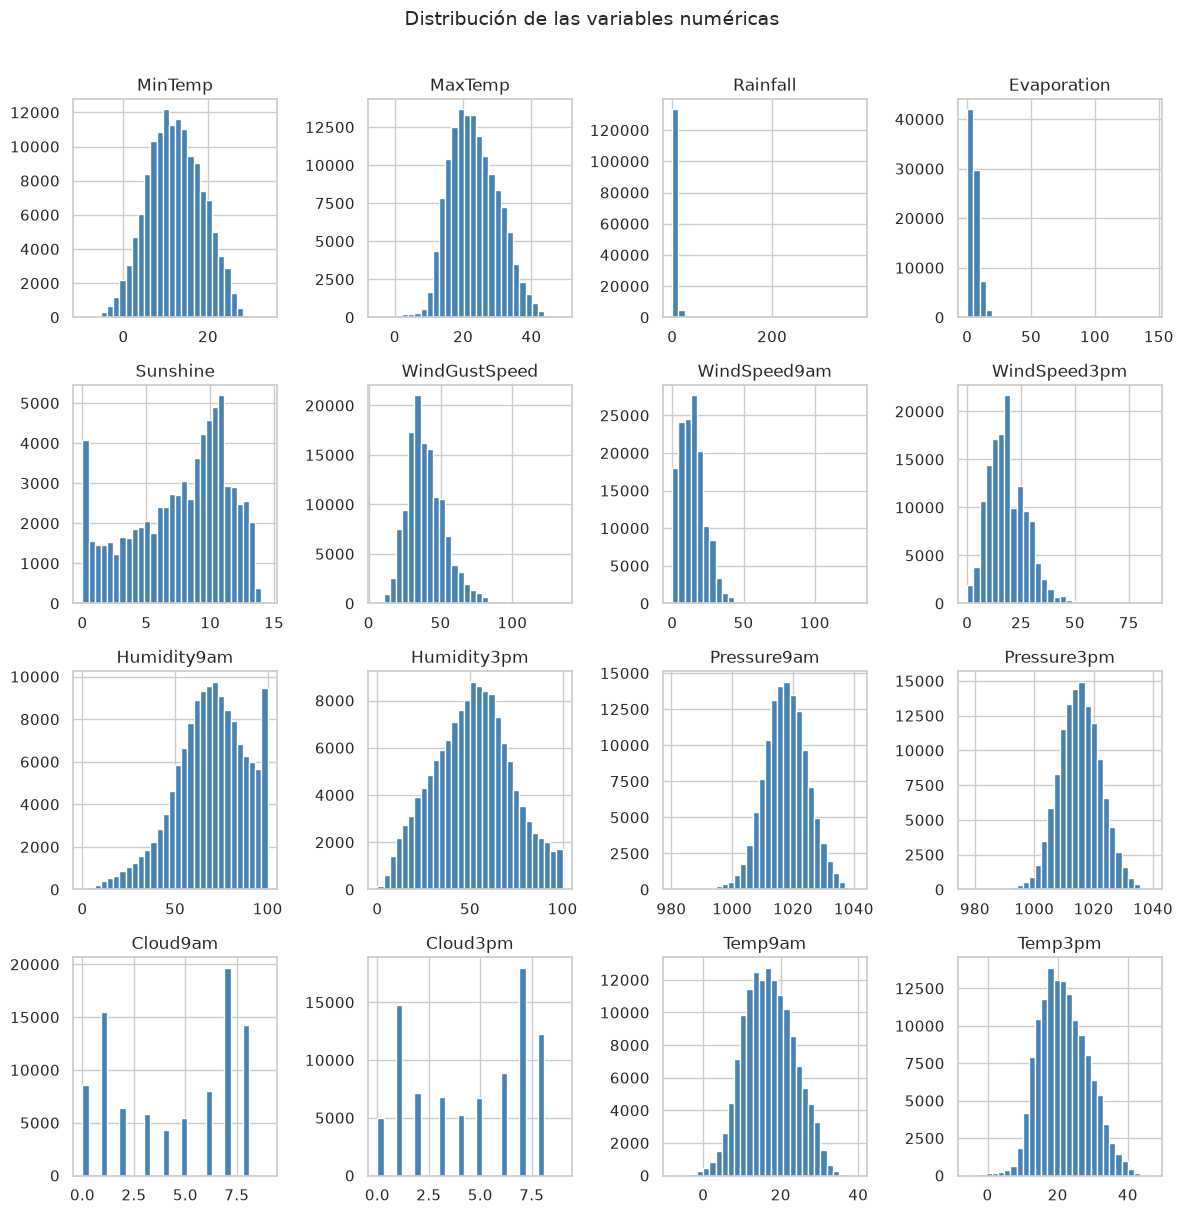

In [13]:
df[num_cols].hist(figsize=(12, 12), bins=30, color='steelblue', edgecolor='white')
plt.suptitle('Distribución de las variables numéricas', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


Cloud9am y Cloud3pm muestran un patrón bimodal.

Rainfall y Evaporation están fuertemente sesgadas a la derecha.

Las características de temperatura y presión siguen una distribución cercana a la normal.

### 3.3 Diagramas de caja según RainTomorrow

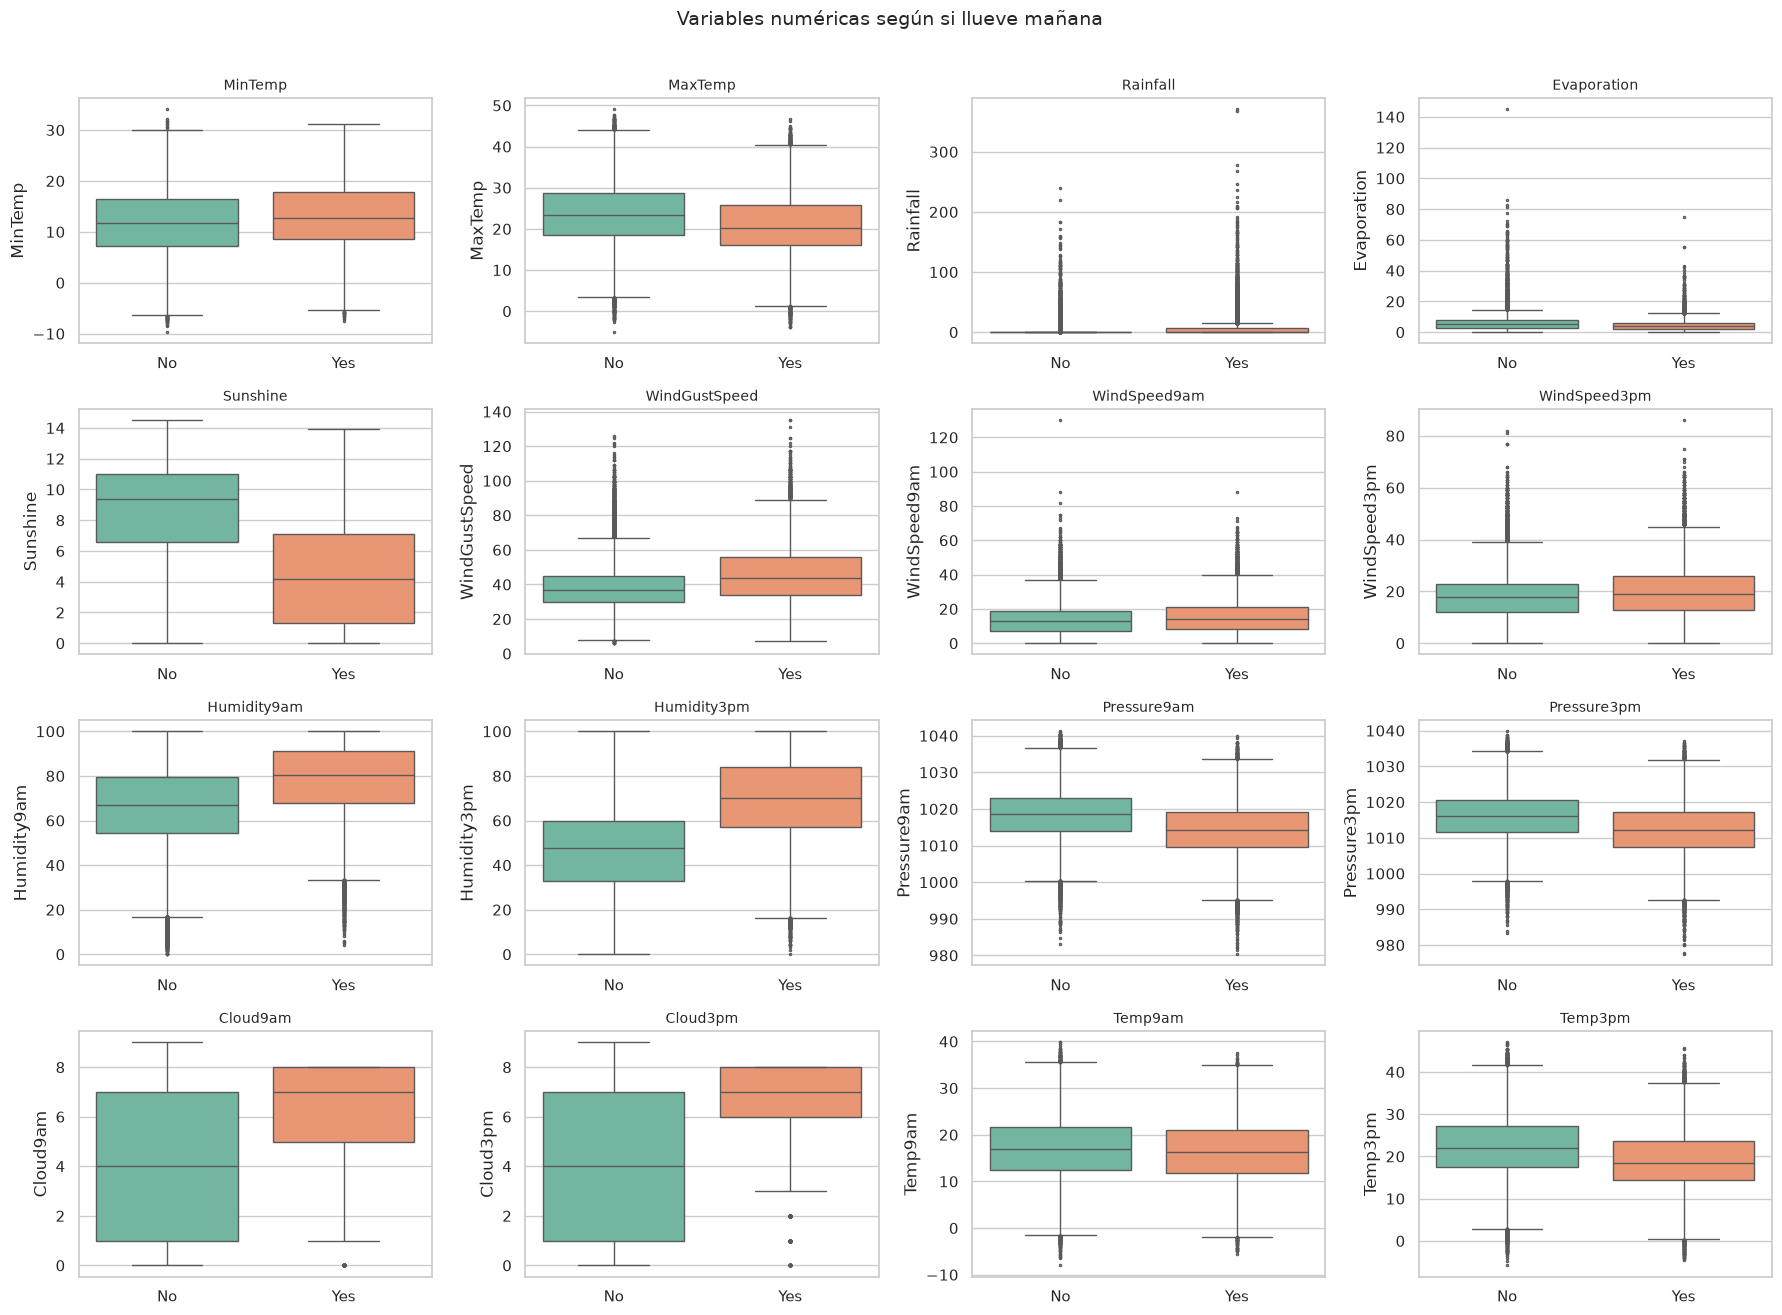

In [14]:
fig, axes = plt.subplots(4, 4, figsize=(18, 13))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="RainTomorrow", y=c, ax=ax, palette="Set2", fliersize=1.5)
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.suptitle("Variables numéricas según si llueve mañana", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

### 3.4 Variables categóricas y estacionalidad

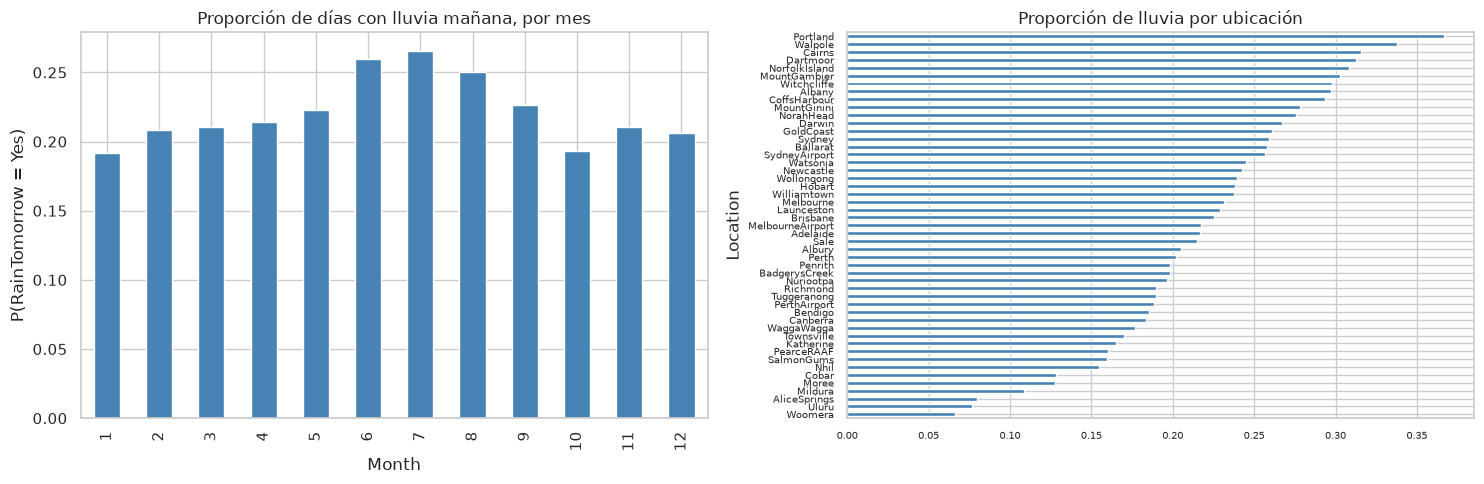

In [15]:
df["Month"] = df["Date"].dt.month
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

(df.groupby("Month")["RainTomorrow"].apply(lambda s: (s == "Yes").mean())
   .plot(kind="bar", ax=axes[0], color="steelblue"))
axes[0].set_title("Proporción de días con lluvia mañana, por mes"); axes[0].set_ylabel("P(RainTomorrow = Yes)")

(df.groupby("Location")["RainTomorrow"].apply(lambda s: (s == "Yes").mean())
   .sort_values().plot(kind="barh", ax=axes[1], color="steelblue", fontsize=7))
axes[1].set_title("Proporción de lluvia por ubicación")

plt.tight_layout(); plt.show()

## 4. Análisis bivariado



### 4.1 Matriz de correlación

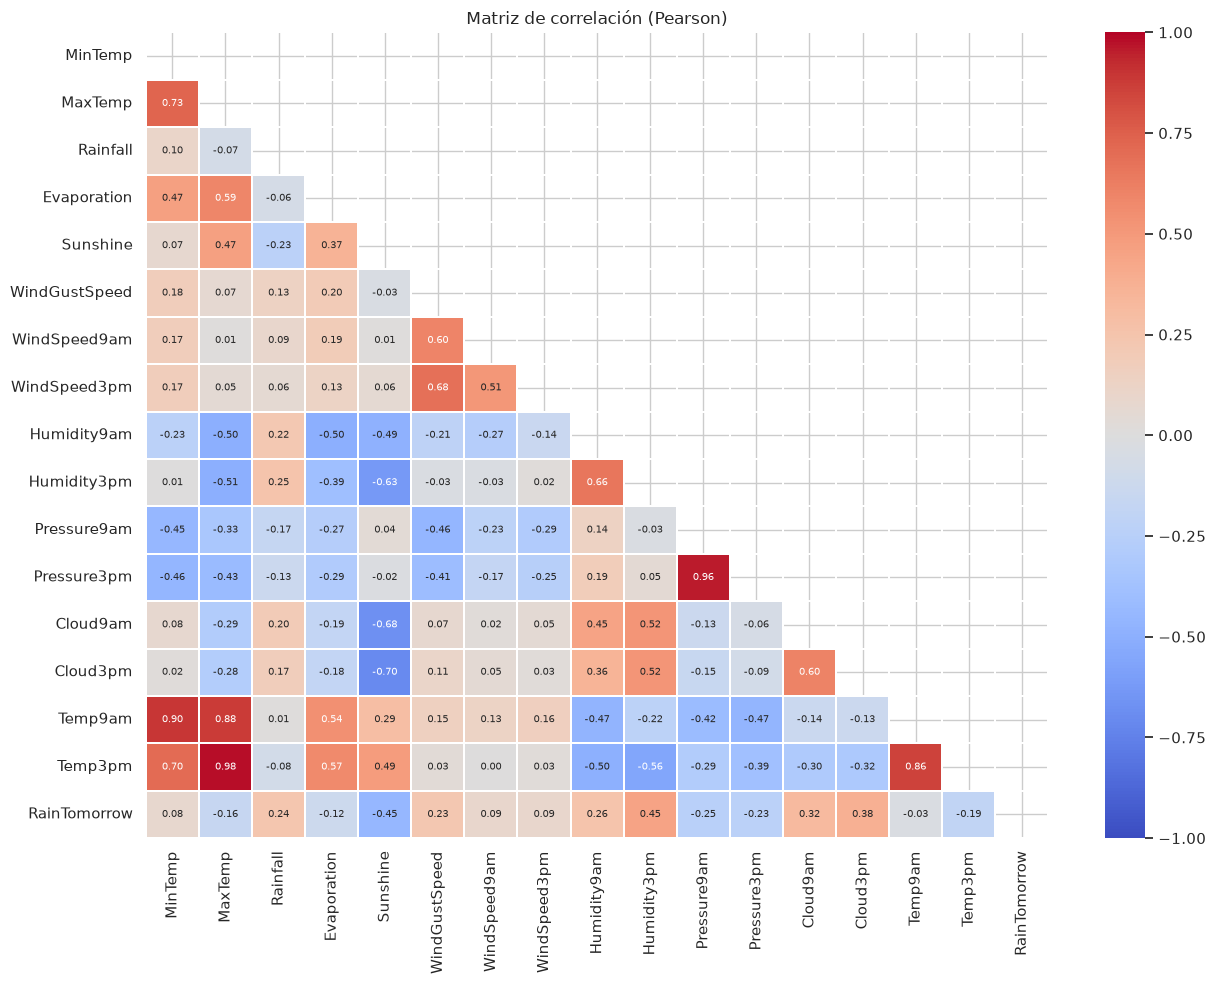

In [16]:
corr_df = df[num_cols].copy()
corr_df["RainTomorrow"] = (df["RainTomorrow"] == "Yes").astype(int)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=0.3, ax=ax)
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout(); plt.show()

In [17]:
# Correlación de cada variable con el target
print(corr["RainTomorrow"].drop("RainTomorrow").sort_values(key=abs, ascending=False).round(3))

# Pares muy correlacionados entre sí (multicolinealidad)
pairs = (corr.drop(index="RainTomorrow", columns="RainTomorrow").abs().where(np.triu(np.ones((len(num_cols),)*2), 1).astype(bool))
             .stack().sort_values(ascending=False))
print("\nPares con |r| > 0.7:")
print(pairs[pairs > 0.7].round(3))

Sunshine        -0.4520
Humidity3pm      0.4470
Cloud3pm         0.3820
Cloud9am         0.3170
Humidity9am      0.2570
Pressure9am     -0.2480
Rainfall         0.2390
WindGustSpeed    0.2340
Pressure3pm     -0.2280
Temp3pm         -0.1920
MaxTemp         -0.1590
Evaporation     -0.1190
WindSpeed9am     0.0890
WindSpeed3pm     0.0870
MinTemp          0.0840
Temp9am         -0.0250
Name: RainTomorrow, dtype: float64

Pares con |r| > 0.7:
MaxTemp      Temp3pm       0.9800
Pressure9am  Pressure3pm   0.9600
MinTemp      Temp9am       0.8960
MaxTemp      Temp9am       0.8820
Temp9am      Temp3pm       0.8550
MinTemp      MaxTemp       0.7320
Sunshine     Cloud3pm      0.7050
MinTemp      Temp3pm       0.7040
dtype: float64


* Con el target (RainTomorrow) las correlaciones más fuertes son: **Sunshine (−0.45)**, **Humidity3pm (+0.45)**, **Cloud3pm (+0.38)**, Cloud9am (+0.32), Humidity9am (+0.26), Pressure9am (−0.25), Rainfall (+0.24) y WindGustSpeed (+0.23). Esto coincide con la intuición meteorológica.
* Hay **multicolinealidad** entre variables que miden casi lo mismo: Temp3pm–MaxTemp (|r| ≈ 0.98), Pressure9am–Pressure3pm (≈ 0.96), Temp9am–MinTemp (≈ 0.90), Temp9am–MaxTemp (≈ 0.88), etc.
* En regresión logística la multicolinealidad **no arruina la predicción**, pero vuelve **inestables e interpretables con dificultad los coeficientes**. Se usa regularización L2 (por defecto en LogisticRegression), que la mitiga. Conservamos todas las variables, pero debemos tenerlo presente al interpretar los coeficientes.

## 6. Preparación de variables y codificación de categóricas

* Se descartan `RainfallTomorrow` (fuga) y `Date` (se conserva el mes).
* **WindGusDir / WindDir9am / WindDir3pm** como variables cíclicas (`sin`/`cos`) para que direcciones de viento como E y ENE queden "próximas".
* **Mes** como variable cíclica (`sin`/`cos`) para que diciembre y enero queden "cerca".
* **`RainToday`** y target pasan a 0/1 (codificación binaria).
* **`log1p`** en `Rainfall` y `Evaporation` (muy asimétricas).
* **Indicadoras de faltante** para `Evaporation`, `Sunshine`, `Cloud9am`, `Cloud3pm`.
* **One-hot encoding** para `Location`. Se usa `drop_first=True` para evitar la trampa de variables dummy (colinealidad perfecta).

> Se usa one-hot y no codificación ordinal (0, 1, 2…) porque estas categorías **no tienen un orden natural** y la regresión logística interpretaría la numeración como una magnitud.

In [18]:
# Variables categóricas de vientos ("WindGustDir", "WindDir9am", "WindDir3pm")

# Configuración inicial del mapeo de viento (16 direcciones)
direcciones_viento = [
    "E",
    "ENE",
    "NE",
    "NNE",
    "N",
    "NNW",
    "NW",
    "WNW",
    "W",
    "WSW",
    "SW",
    "SSW",
    "S",
    "SSE",
    "SE",
    "ESE",
]
mapeo_viento = {dir_texto: i for i, dir_texto in enumerate(direcciones_viento)}

# Ordenamiento Cronológico
df = df.sort_values("Date").reset_index(drop=True)

# Imputación Temporal por Arrastre (ffill + bfill) combinados por si falta el primero.
# Rellenamos los NaN con el último valor válido anterior.
# Si el primer registro es NaN, bfill usa el primer valor posterior válido.
df["WindGustDir"] = df["WindGustDir"].ffill().bfill()
df["WindDir9am"] = df["WindDir9am"].ffill().bfill()
df["WindDir3pm"] = df["WindDir3pm"].ffill().bfill()

# Codificación Cíclica Seno/Coseno
# Convertimos el texto imputado a su índice correspondiente (0 al 15)
df["WindGustDir_idx"] = df["WindGustDir"].map(mapeo_viento)
df["WindDir9am_idx"] = df["WindDir9am"].map(mapeo_viento)
df["WindDir3pm_idx"] = df["WindDir3pm"].map(mapeo_viento)


# Aplicamos las fórmulas trigonométricas (N = 16)
df["WindGustDir_sin"] = np.sin(2 * np.pi * df["WindGustDir_idx"] / 16)
df["WindGustDir_cos"] = np.cos(2 * np.pi * df["WindGustDir_idx"] / 16)
df["WindDir9am_sin"] = np.sin(2 * np.pi * df["WindDir9am_idx"] / 16)
df["WindDir9am_cos"] = np.cos(2 * np.pi * df["WindDir9am_idx"] / 16)
df["WindDir3pm_sin"] = np.sin(2 * np.pi * df["WindDir3pm_idx"] / 16)
df["WindDir3pm_cos"] = np.cos(2 * np.pi * df["WindDir3pm_idx"] / 16)


# Eliminamos columnas intermedias que ya no necesitamos para el modelo
df = df.drop(columns=["WindGustDir", "WindGustDir_idx",
                      "WindDir9am", "WindDir9am_idx",
                      "WindDir3pm", "WindDir3pm_idx"]
             )

In [19]:
data = df.drop(columns=["RainfallTomorrow"]).copy()

# --- indicadoras de faltante (antes de imputar)
#     Creamos la columna xx_faltante que indica si la variable xx está faltante (1) o no (0)
for c in faltante_alto:
    data[f"{c}_faltante"] = data[c].isna().astype(int)

# --- estacionalidad
#     Hace que diciembre y enero estén cerca.
data["Mes_impar"] = np.sin(2 * np.pi * data["Month"] / 12)
data["Mes_par"] = np.cos(2 * np.pi * data["Month"] / 12)

# --- binarizamos "RainToday y "RainTomorrow" que es nuestra variable objetivo (target)
data["RainToday"] = (data["RainToday"] == "Yes").astype(int)
y = (data["RainTomorrow"] == "Yes").astype(int) #variable objetivo (target)

# --- transformación log para variables con distribución sesgada (skew > 1)
data["Rainfall"] = np.log1p(data["Rainfall"])
data["Evaporation"] = np.log1p(data["Evaporation"])

# drop_first=True para evitar la trampa de variables dummy que pueden generar multicolinealidad.
# La primera columna de cada variable se puede deducir con las demás. 
# El orden de las columnas one-hot es alfabético.
X = data.drop(columns=["RainTomorrow", "Date", "Month"])
X = pd.get_dummies(X, columns=["Location"], drop_first=True, dtype=int)

print("Shape de X:", X.shape, "| y:", y.shape)
print("Columnas:", X.shape[1], "(numéricas + indicadoras + one-hot)")
X.head(10)

Shape de X: (140747, 77) | y: (140747,)
Columnas: 77 (numéricas + indicadoras + one-hot)


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos,Evaporation_faltante,Sunshine_faltante,Cloud9am_faltante,Cloud3pm_faltante,Mes_impar,Mes_par,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera
0,7.9000,24.3000,0.0000,1.4816,6.3000,29.0000,7.0000,20.0000,63.9000,28.1000,1020.3000,1014.7000,7.0000,7.0000,14.4000,23.5000,0,0.7071,-0.7071,-0.7071,-0.7071,0.7071,-0.7071,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,13.3000,27.0000,1.5261,1.6864,9.7000,38.0000,5.0000,14.0000,79.4000,35.8000,1012.1000,1008.5000,5.0000,3.0000,17.4000,25.6000,1,0.3827,0.9239,0.0000,1.0000,0.0000,-1.0000,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,13.9000,23.1000,1.5261,1.9169,3.3000,84.0000,5.0000,6.0000,80.9000,68.8000,1009.6000,1007.4000,8.0000,7.0000,15.3000,20.0000,1,0.7071,-0.7071,1.0000,0.0000,0.9239,0.3827,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,13.0000,15.8000,3.7087,2.1041,9.1000,54.0000,30.0000,23.0000,62.7000,55.9000,1005.4000,1007.0000,2.0000,7.0000,13.1000,13.3000,1,0.7071,-0.7071,0.3827,-0.9239,0.0000,-1.0000,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,7.8000,16.4000,1.3350,1.8871,10.6000,49.0000,19.0000,28.0000,67.5000,50.1000,1018.4000,1018.6000,7.0000,7.0000,11.4000,15.9000,1,-0.9239,0.3827,-0.9239,0.3827,-0.3827,0.9239,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,7.5000,17.6000,0.0000,1.9169,8.2000,46.0000,18.0000,22.0000,70.0000,57.2000,1023.6000,1021.4000,7.0000,5.0000,11.1000,14.5000,0,-0.7071,0.7071,-0.7071,0.7071,0.0000,1.0000,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,6.3000,18.4000,0.1823,1.6487,8.4000,46.0000,20.0000,27.0000,61.8000,47.6000,1024.8000,1022.6000,4.0000,6.0000,12.0000,17.0000,0,-0.7071,0.7071,-0.7071,0.7071,-0.3827,0.9239,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,8.6000,16.8000,0.0000,1.8871,4.6000,43.0000,13.0000,24.0000,67.6000,56.6000,1026.1000,1023.8000,6.0000,7.0000,12.6000,15.8000,0,0.0000,1.0000,-0.7071,0.7071,0.0000,1.0000,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,8.7000,18.7000,0.0000,1.6094,4.1000,51.0000,19.0000,16.0000,69.9000,47.2000,1025.8000,1022.4000,7.0000,7.0000,14.9000,18.9000,0,-1.0000,-0.0000,0.0000,1.0000,0.3827,0.9239,0,0,0,0,-0.5000,0.8660,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,7.8000,23.1000,2.8449,1.8563,7.7000,30.0000,5.0000,5.0000,83.6000,29.7000,1024.3000,1020.8000,7.000

## 7. División train / validación / test

Para abordar un problema de predicción de lluvias con series temporales, el mayor peligro es el leakage (fuga de datos) o romper la estructura del tiempo al usar divisiones aleatorias, con train_test_split tradicional.

Para asegurar la consistencia temporal, previamente ordenamos el DataFrame en forma explícita por la columna de fecha en sentido ascendente, y luego hacemos la división en forma estrictamente cronológica.

* **Train (60 % más antiguo)**: ajusta el modelo.
* **Validación (20 % intermedio)**: se usa para elegir el umbral y comparar configuraciones.
* **Test (20 % final)**: se usa una sola vez al final para reportar el desempeño.

Se divide antes de imputar y estandarizar, para que la mediana y la media/desvío se calculen solo con los datos de entrenamiento (si no, el test "se filtra" en el preprocesamiento).

In [20]:
n = len(X)
train_end = int(n * 0.60)
val_end = int(n * 0.80)

X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:val_end].copy()
X_test = X.iloc[val_end:].copy()

y_train = y.iloc[:train_end].copy()
y_val = y.iloc[train_end:val_end].copy()
y_test = y.iloc[val_end:].copy()

for nombre, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{nombre:5s}: {len(yy):>7,} filas | % lluvia = {yy.mean():.3%}")

train:  84,448 filas | % lluvia = 22.420%
val  :  28,149 filas | % lluvia = 21.471%
test :  28,150 filas | % lluvia = 22.092%


## 8. Imputación y estandarización (ajustadas solo con train)

La **estandarización** es importante para la regresión logística porque:
* los coeficientes quedan comparables entre variables (están en la misma escala),
* la regularización L2 penaliza por igual a todas las variables (si no, las de mayor escala quedarían favorecidas).

Solo se estandarizan las variables **continuas**; las dummies 0-1 se dejan como están.

In [21]:
continuas = ["MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine", "WindGustSpeed",
             "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm",
             "Cloud9am", "Cloud3pm", "Temp9am", "Temp3pm"]

imputer = SimpleImputer(strategy="median").fit(X_train[continuas])      # mediana de TRAIN
scaler = StandardScaler().fit(imputer.transform(X_train[continuas]))    # media y desvío de TRAIN

def preprocesar(Xd):
    Xd = Xd.copy()
    Xd[continuas] = scaler.transform(imputer.transform(Xd[continuas]))
    return Xd

X_train_s, X_val_s, X_test_s = preprocesar(X_train), preprocesar(X_val), preprocesar(X_test)


## 9. Regresión logística

### 9.1 Definimos una función para calculas las métricas.

Definimos el umbral por defecto con umbral=0.5 (ajustable)

In [22]:
# Función para evaluar un modelo con varias métricas, dado un umbral
def metricas(modelo, X, y, umbral=0.5):
    proba = modelo.predict_proba(X)[:, 1]
    pred = (proba >= umbral).astype(int)
    return {
        "accuracy": accuracy_score(y, pred),
        "balanced_acc": balanced_accuracy_score(y, pred),
        "precision": precision_score(y, pred),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, proba),
        "pr_auc": average_precision_score(y, proba),
        "mcc": matthews_corrcoef(y, pred),        
        "log_loss": log_loss(y, proba),
        "brier": brier_score_loss(y, proba),
    }

def graficar_cm(y_true, y_pred, titulo, ax):
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=["No llueve", "Llueve"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",d")
    ax.set_title(titulo, fontsize=10); ax.grid(False)

def metricas_desde_scores(y_true, pred, proba, nombre):
    return {
        "Modelo": nombre,
        "accuracy": accuracy_score(y_true, pred),
        "balanced_acc": balanced_accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "mcc": matthews_corrcoef(y_true, pred),
        "log_loss": log_loss(y_true, proba),
        "brier": brier_score_loss(y_true, proba),
    }
# accuracy: proporción de predicciones correctas
# balanced_acc: accuracy balanceada (útil para datasets desbalanceados)
# precision: proporción de predicciones positivas que son correctas
# recall: proporción de ejemplos positivos que son correctamente predichos
# f1: media armónica de precision y recall
# roc_auc: área bajo la curva ROC
# pr_auc: área bajo la curva de precisión-recall (útil para datasets desbalanceados, evalua el modelo en todos los umbrales)
# mcc: coeficiente de correlación de Matthews (útil para datasets desbalanceados, evalua el modelo en todos los umbrales)
# log_loss: pérdida logarítmica
# brier: pérdida de Brier

**accuracy**: proporción de predicciones correctas

**balanced_acc**: accuracy balanceada (útil para datasets desbalanceados)

**precision**: proporción de predicciones positivas que son correctas

**recall**: proporción de ejemplos positivos que son correctamente predichos

**f1**: media armónica de precision y recall

**roc_auc**: área bajo la curva ROC

**pr_auc**: área bajo la curva de precisión-recall, útil para datasets desbalanceados (evalua el modelo en todos los umbrales)

**mcc**: coeficiente de correlación de Matthews (útil para datasets desbalanceados). El resultado de la función siempre se sitúa en un rango estricto de -1 a +1. (Predicción perfecta: +1, Predicción aleatoria: 0, Predicción inversa: -1)

**log_loss**: pérdida logarítmica

**brier**: pérdida de Brier

## 9.2 Se entrenan dos modelos y se comparan.

- Regresión logística estandar (lr)
- Regresión logística con class_weight="balanced" para que tenga en cuenta la clase minoritaria "No llueve" (lr_bal)

In [23]:
# Regresión logística sin y con class_weight, para ver cómo afecta el desbalance
# Regularización Ridge L2 por defecto (penalty='l2')
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_s, y_train)
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced",
                            random_state=RANDOM_STATE).fit(X_train_s, y_train)

modelos = {
    "RL estándar": lr,
    "RL class_weight=balanced": lr_bal
}

# Probabilidades P(llueve) en validación y test
proba_val = {n: m.predict_proba(X_val_s)[:, 1] for n, m in modelos.items()}
proba_test = {n: m.predict_proba(X_test_s)[:, 1] for n, m in modelos.items()}



### 9.3 Metricas con el umbral por defecto (0.5)

In [24]:
res = pd.DataFrame({
    "LogReg": metricas(lr, X_val_s, y_val),
    "LogReg balanced": metricas(lr_bal, X_val_s, y_val),
}).T
res

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,mcc,log_loss,brier
LogReg,0.8485,0.7170,0.7170,0.4866,0.5797,0.8684,0.6843,0.5052,0.3492,0.1093
LogReg balanced,0.8025,0.7827,0.5283,0.7480,0.6192,0.8694,0.6820,0.5047,0.4323,0.1389


### 9.4 Matrices de confusión (umbral 0.5, sobre validación)
Atención porque las matrices están traspuestas respecto a lo visto en la teoría (estándar de sklearn)

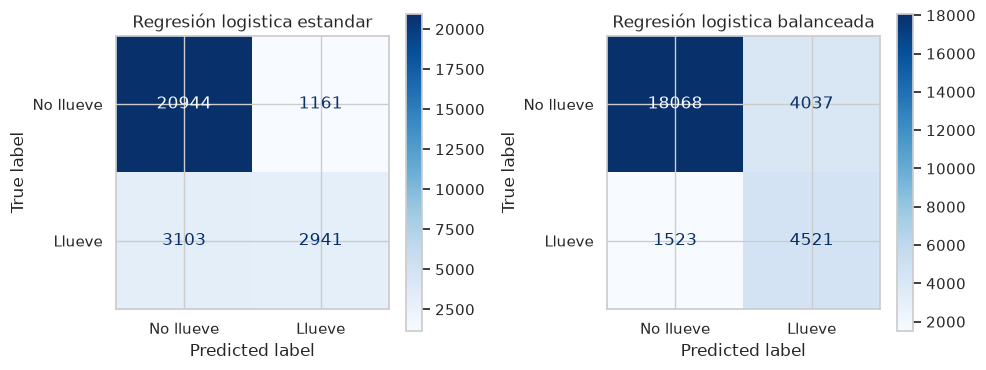

Ubicación de las columas de la matriz de confusión - Y según la teoría
               VN  |  FP                                VP  |  FP
               ---------                                ---------
               FN  |  VP                                FN  |  VN


In [25]:
# Matrices de confusión en validación (umbral 0.5)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, m) in zip(axes, [("Regresión logistica estandar", lr), ("Regresión logistica balanceada", lr_bal)]):
    ConfusionMatrixDisplay.from_estimator(m, X_val_s, y_val, ax=ax, cmap="Blues",
                                          display_labels=["No llueve", "Llueve"])
    ax.set_title(nombre)
plt.tight_layout(); plt.show()

print("Ubicación de las columas de la matriz de confusión - Y según la teoría")
print("               VN  |  FP                                VP  |  FP")
print("               ---------                                ---------")
print("               FN  |  VP                                FN  |  VN")

### Falsos positivos vs. falsos negativos

- **Falso positivo (FP):** el modelo predice *"llueve mañana"* y **no llueve** (una falsa alarma).
- **Falso negativo (FN):** el modelo predice *"no llueve"* y **sí llueve**. 

**¿Cuál es más grave?** Depende de la aplicación. Para un pronóstico general, un FN (no avisar de la lluvia) suele ser **más costoso** que un FP (avisar de más), así que interesa un **recall alto**. Si en cambio la alarma tiene un costo grande (p. ej. cancelar un evento), pesa más la **precision**. Esta decisión se traduce en la elección del umbral.

Se ve que el **modelo estándar comete muchos más FN** (recall bajo, por el desbalance), mientras que `class_weight="balanced"` **baja los FN a costa de más FP**.

### 9.5 Curvas ROC

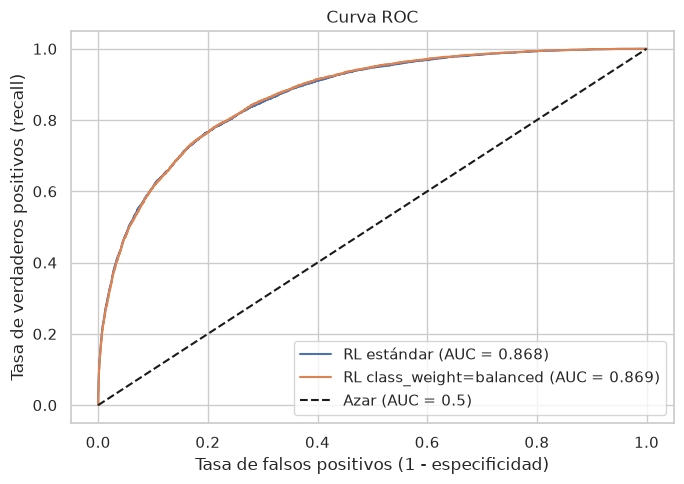

In [26]:
fig, ax = plt.subplots(figsize=(7, 5))

for n in modelos:
  fpr, tpr, _ = roc_curve(y_val, proba_val[n])
  ax.plot(
      fpr, tpr, label=f"{n} (AUC = {roc_auc_score(y_val, proba_val[n]):.3f})"
  )

ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set(
    xlabel="Tasa de falsos positivos (1 - especificidad)",
    ylabel="Tasa de verdaderos positivos (recall)",
    title="Curva ROC",
)

ax.legend(loc="best")
plt.tight_layout()
plt.show()

**Interpretación:** ambas variantes tienen **prácticamente la misma curva ROC** (mismo AUC). Es esperable: `class_weight` solo cambia cuánto "pesa" cada clase en el entrenamiento, y reordena muy poco los puntajes; lo que realmente cambia es **en qué punto de la curva queda ubicado el umbral 0.5**. Cada punto de la curva corresponde a un umbral distinto: moverse hacia arriba/derecha = más recall a costa de más falsos positivos.

### 9.6 Elección del umbral: ¿0.5 es el mejor?

**No necesariamente.** 0.5 es el umbral "natural" si las clases estuvieran balanceadas y los errores costaran lo mismo. Acá ninguna de las dos cosas se cumple. Formas de elegirlo (siempre **sobre validación**, nunca sobre test):

1. **Índice de Youden (J = TPR − FPR):** el punto de la ROC más alejado de la diagonal. Equilibra sensibilidad y especificidad.
2. **Maximizar F1** recorriendo la curva Precision-Recall: equilibra precision y recall sobre la clase positiva.
3. **Punto más cercano a (0, 1)** en la ROC.
4. **Basado en costos:** si un FN cuesta `c_FN` y un FP cuesta `c_FP`, se minimiza el costo esperado `c_FN·FN + c_FP·FP`. El umbral óptimo teórico es `c_FP / (c_FP + c_FN)`.
5. **Fijar un recall mínimo** (p. ej. 80 %) y quedarse con la mayor precision posible.

In [27]:
def umbral_youden(y_true, score):
    fpr, tpr, thr = roc_curve(y_true, score)
    return thr[np.argmax(tpr - fpr)]

def umbral_f1(y_true, score):
    p, r, thr = precision_recall_curve(y_true, score)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return thr[np.argmax(f1)]

def umbral_costo(y_true, score, c_fn=2.0, c_fp=1.0):
    grid = np.linspace(0.01, 0.99, 197)
    costos = [c_fn * ((score < t) & (y_true == 1)).sum() + c_fp * ((score >= t) & (y_true == 0)).sum() for t in grid]
    return grid[int(np.argmin(costos))]

umbrales = {}
filas = []
for n in modelos:
    umbrales[n] = {
        "0.5 (defecto)": 0.5,
        "Youden": umbral_youden(y_val, proba_val[n]),
        "Máx. F1": umbral_f1(y_val, proba_val[n]),
        "Costo (FN=2×FP)": umbral_costo(y_val, proba_val[n]),
    }
    
for nombre_u, t in umbrales[n].items():
    pred = (proba_val[n] >= t).astype(int)

    d = {
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall (Sensib.)": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "Balanced Acc.": balanced_accuracy_score(y_val, pred),
        "MCC": matthews_corrcoef(y_val, pred),
    }

    filas.append({
        "Modelo": n,
        "Criterio": nombre_u,
        "Umbral": t,
        **d
    })

tabla_umbrales = pd.DataFrame(filas)
tabla_umbrales.round(4)

,Modelo,Criterio,Umbral,Accuracy,Precision,Recall (Sensib.),F1,Balanced Acc.,MCC
0,RL class_weight=balanced,0.5 (defecto),0.5000,0.8025,0.5283,0.7480,0.6192,0.7827,0.5047
1,RL class_weight=balanced,Youden,0.4585,0.7877,0.5036,0.7783,0.6115,0.7843,0.4958
2,RL class_weight=balanced,Máx. F1,0.5339,0.8131,0.5492,0.7232,0.6243,0.7804,0.5114
3,RL class_weight=balanced,Costo (FN=2×FP),0.6500,0.8369,0.6207,0.6186,0.6197,0.7576,0.5159


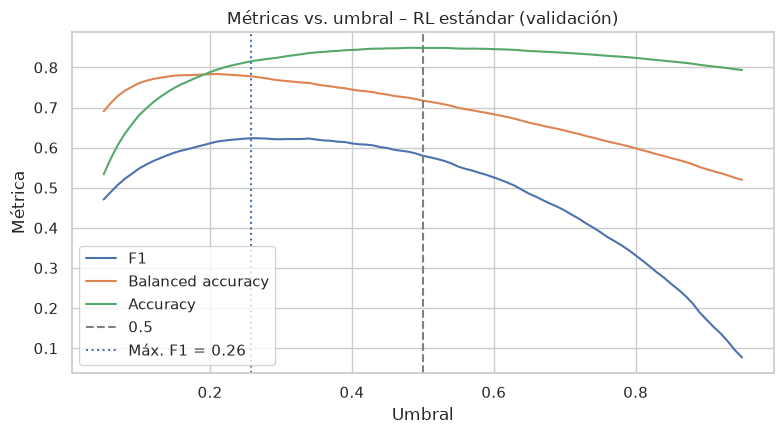

In [28]:
# F1 y balanced accuracy en función del umbral (RL estándar)
n = "RL estándar"
grid = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_val, (proba_val[n] >= t).astype(int)) for t in grid]
bas = [balanced_accuracy_score(y_val, (proba_val[n] >= t).astype(int)) for t in grid]
accs = [accuracy_score(y_val, (proba_val[n] >= t).astype(int)) for t in grid]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid, f1s, label="F1"); ax.plot(grid, bas, label="Balanced accuracy"); ax.plot(grid, accs, label="Accuracy")
ax.axvline(0.5, color="gray", ls="--", label="0.5")
ax.axvline(umbrales[n]["Máx. F1"], color="C0", ls=":", label=f"Máx. F1 = {umbrales[n]['Máx. F1']:.2f}")
ax.set(xlabel="Umbral", ylabel="Métrica", title=f"Métricas vs. umbral – {n} (validación)"); ax.legend()
plt.tight_layout(); plt.show()

**Conclusión sobre el umbral:** para el modelo estándar, **0.5 no es el mejor** si se busca un buen equilibrio entre las clases: el umbral que maximiza F1 es **notablemente menor** (≈ 0.26), lo que sube el recall de ≈ 0.52 a ≈ 0.67 con una caída moderada de la precision y de la accuracy. La accuracy es máxima cerca de 0.5, pero a costa de dejar pasar casi la mitad de los días de lluvia: otra muestra de por qué no conviene guiarse solo por accuracy. Con `class_weight="balanced"` ocurre lo inverso: el reponderado ya "infla" las probabilidades de lluvia, así que el umbral que maximiza F1 queda **por encima** de 0.5 (≈ 0.61). Ambos modelos terminan en un F1 y un MCC casi idénticos: el reponderado y el cambio de umbral son dos formas de mover el mismo punto de operación.

Se elige para el modelo final el umbral de **máximo F1 calculado en validación** (se puede cambiar por el de costo si se justifica otro costo relativo FN/FP).

In [29]:
# Evaluación final en TEST con el umbral elegido en validación
umbral_final = {n: umbrales[n]["Máx. F1"] for n in modelos}

res_test = []
for n, modelo in modelos.items():
    for etiqueta, t in [
        ("0.5", 0.5),
        (f"{umbral_final[n]:.2f}", umbral_final[n]),
    ]:
        d = metricas(modelo, X_test_s, y_test, umbral=t)
        d["Modelo"] = f"{n} | umbral {etiqueta}"
        res_test.append(d)

pd.DataFrame(res_test).set_index("Modelo").round(4)

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,mcc,log_loss,brier
Modelo,,,,,,,,,,
RL estándar | umbral 0.5,0.8440,0.7105,0.7268,0.4713,0.5718,0.8581,0.6803,0.4986,0.3640,0.1132
RL estándar | umbral 0.26,0.8142,0.7683,0.5656,0.6860,0.6200,0.8581,0.6803,0.5026,0.3640,0.1132
RL class_weight=balanced | umbral 0.5,0.8032,0.7746,0.5407,0.7234,0.6189,0.8594,0.6782,0.4993,0.4392,0.1403
RL class_weight=balanced | umbral 0.53,0.8125,0.7716,0.5607,0.6985,0.6220,0.8594,0.6782,0.5047,0.4392,0.1403


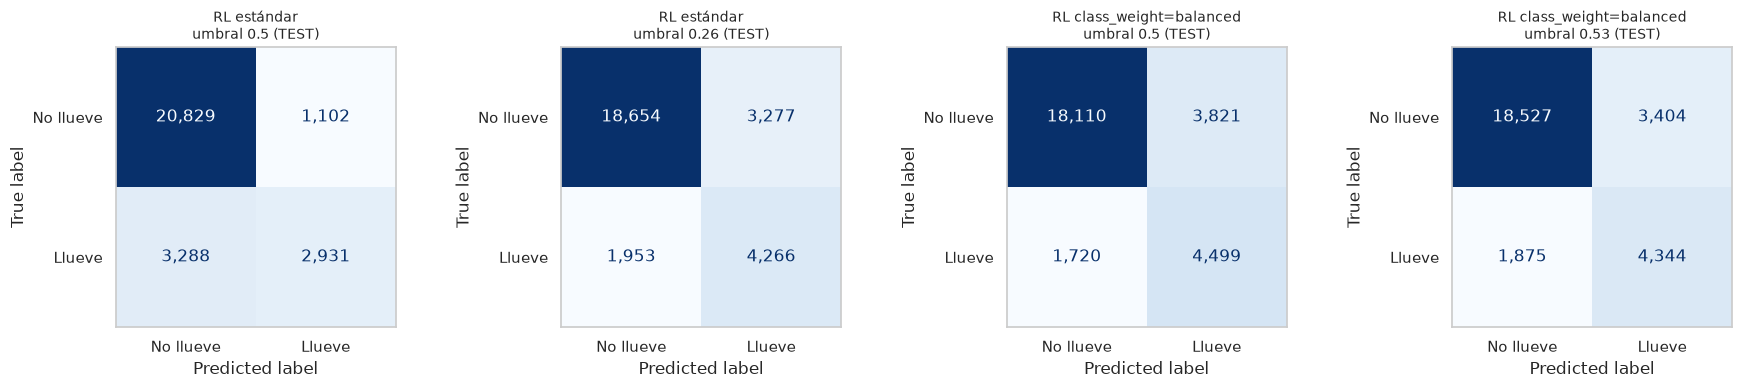

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
i = 0
for n in modelos:
    for t, lab in [(0.5, "0.5"), (umbral_final[n], f"{umbral_final[n]:.2f}")]:
        graficar_cm(y_test, (proba_test[n] >= t).astype(int), f"{n}\numbral {lab} (TEST)", axes[i]); i += 1
plt.tight_layout(); plt.show()

## 9.7 ¿Se consiguió un buen fitting?

Se evalúa con:
1. Comparación de métricas **train vs. validación vs. test** (si train ≫ val → sobreajuste; si ambas son bajas → subajuste).
2. **Curva de aprendizaje** (¿más datos ayudan?).
3. Efecto de la **regularización** (`C`).

In [31]:
filas = []
modelo = modelos["RL estándar"]

for nombre_split, Xs, ys in [
    ("train", X_train_s, y_train),
    ("validación", X_val_s, y_val),
    ("test", X_test_s, y_test),
]:
    d = metricas(modelo, Xs, ys, umbral=0.5)
    filas.append({
        "Modelo": nombre_split,
        "Accuracy": d["accuracy"],
        "F1": d["f1"],
        "ROC-AUC": d["roc_auc"],
        "PR-AUC": d["pr_auc"],
        "Log-loss": d["log_loss"],
    })

pd.DataFrame(filas).set_index("Modelo").round(4)

,Accuracy,F1,ROC-AUC,PR-AUC,Log-loss
Modelo,,,,,
train,0.8528,0.6176,0.8780,0.7192,0.3432
validación,0.8485,0.5797,0.8684,0.6843,0.3492
test,0.8440,0.5718,0.8581,0.6803,0.3640


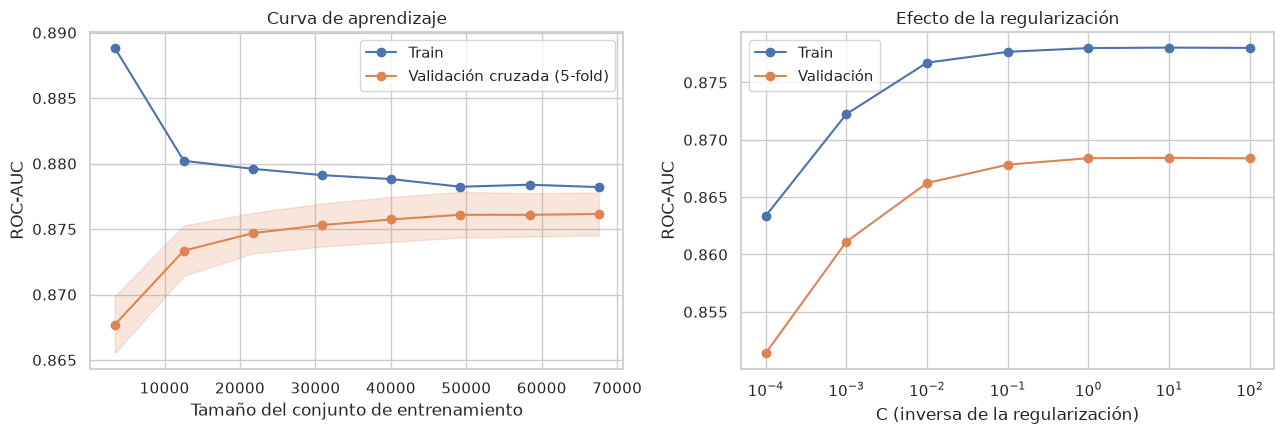

In [32]:
sizes, tr_sc, va_sc = learning_curve(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), X_train_s, y_train,
    train_sizes=np.linspace(0.05, 1.0, 8), cv=5, scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE, shuffle=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sizes, tr_sc.mean(1), "o-", label="Train"); axes[0].plot(sizes, va_sc.mean(1), "o-", label="Validación cruzada (5-fold)")
axes[0].fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.2, color="C1")
axes[0].set(xlabel="Tamaño del conjunto de entrenamiento", ylabel="ROC-AUC", title="Curva de aprendizaje"); axes[0].legend()

Cs = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
auc_tr, auc_va = [], []
for C in Cs:
    m = LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE).fit(X_train_s, y_train)
    auc_tr.append(roc_auc_score(y_train, m.predict_proba(X_train_s)[:, 1]))
    auc_va.append(roc_auc_score(y_val, m.predict_proba(X_val_s)[:, 1]))
axes[1].semilogx(Cs, auc_tr, "o-", label="Train"); axes[1].semilogx(Cs, auc_va, "o-", label="Validación")
axes[1].set(xlabel="C (inversa de la regularización)", ylabel="ROC-AUC", title="Efecto de la regularización"); axes[1].legend()
plt.tight_layout(); plt.show()

**Diagnóstico:**
* Las métricas en **train, validación y test son muy parecidas** y las curvas de aprendizaje/regularización son planas y juntas → **no hay sobreajuste** (varianza baja).
* Que train y validación converjan en un valor "moderado" indica cierto **subajuste leve (sesgo)**: la regresión logística es un modelo **lineal** y no captura interacciones entre variables (p. ej. humedad × presión) ni efectos no lineales. Con más datos no mejora (la curva ya es plana), y regularizar menos/más no cambia el AUC.
* **Conclusión:** el fitting es **razonablemente bueno para un modelo lineal** (ROC-AUC ≈ 0.88, accuracy ≈ 85 % con umbral 0.5), estable y sin sobreajuste; para mejorar habría que agregar **complejidad al modelo** (términos polinómicos, interacciones, árboles/boosting) o más variables (p. ej. rezagos de días anteriores).

## 10. Modelo base (baselines) y comparación

Un **modelo base** fija el piso de desempeño contra el cual se justifica un modelo más complejo. Si la regresión logística no supera claramente a estos baselines, no aporta valor. Se usan tres:

1. **Siempre "No llueve"** (clase mayoritaria) – `DummyClassifier(most_frequent)`.
2. **Aleatorio estratificado** – predice al azar respetando la proporción de clases (`DummyClassifier(stratified)`).
3. **Persistencia (regla simple)**: *"mañana llueve si hoy llovió"* (`RainToday`). Es la regla meteorológica más ingenua y suele ser un baseline difícil de superar en clima.

Se repiten los mismos pasos del punto 9: métricas, matrices de confusión y curvas ROC.

In [33]:
base_mayoritaria = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
base_azar = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(X_train_s, y_train)

# Persistencia: usa la columna RainToday (0/1; no se estandariza porque no es continua)
score_pers_test = X_test_s["RainToday"].values.astype(float)

baselines_test = {
    "Base: siempre 'No llueve'": (base_mayoritaria.predict(X_test_s), np.full(len(y_test), y_train.mean())),
    "Base: estratificado (Azar)": (base_azar.predict(X_test_s), base_azar.predict_proba(X_test_s)[:, 1]),
    "Base: persistencia (RainToday)": (score_pers_test.astype(int), score_pers_test),
}

filas = [
    metricas_desde_scores(y_test, pred, proba, nombre)
    for nombre, (pred, proba) in baselines_test.items()
]

for n in modelos:
    pred = (proba_test[n] >= umbral_final[n]).astype(int)
    filas.append(
        metricas_desde_scores(
            y_test,
            pred,
            proba_test[n],
            f"{n} | umbral {umbral_final[n]:.2f}",
        )
    )

comparacion = pd.DataFrame(filas).set_index("Modelo")
comparacion.round(4)

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc,mcc,log_loss,brier
Modelo,,,,,,,,,,
Base: siempre 'No llueve',0.7791,0.5000,0.0000,0.0000,0.0000,0.5000,0.2209,0.0000,0.5281,0.1721
Base: estratificado (Azar),0.6566,0.5031,0.2257,0.2280,0.2268,0.5031,0.2220,0.0061,12.3778,0.3434
Base: persistencia (RainToday),0.7552,0.6458,0.4464,0.4496,0.4480,0.6458,0.3223,0.2908,8.8221,0.2448
RL estándar | umbral 0.26,0.8142,0.7683,0.5656,0.6860,0.6200,0.8581,0.6803,0.5026,0.3640,0.1132
RL class_weight=balanced | umbral 0.53,0.8125,0.7716,0.5607,0.6985,0.6220,0.8594,0.6782,0.5047,0.4392,0.1403


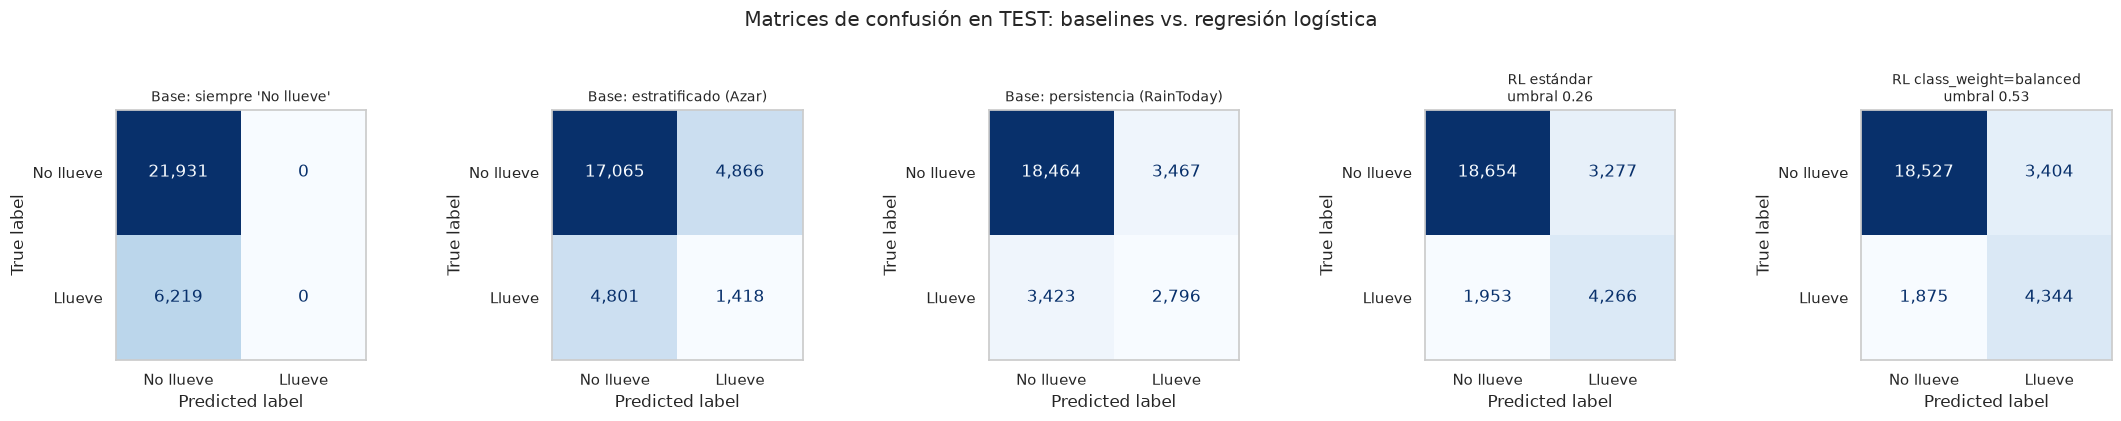

In [34]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
i = 0
for n, (p, s) in baselines_test.items():
    graficar_cm(y_test, p, n, axes[i]); i += 1
for n in modelos:
    graficar_cm(y_test, (proba_test[n] >= umbral_final[n]).astype(int), f"{n}\numbral {umbral_final[n]:.2f}", axes[i]); i += 1
plt.suptitle("Matrices de confusión en TEST: baselines vs. regresión logística", y=1.03)
plt.tight_layout(); plt.show()

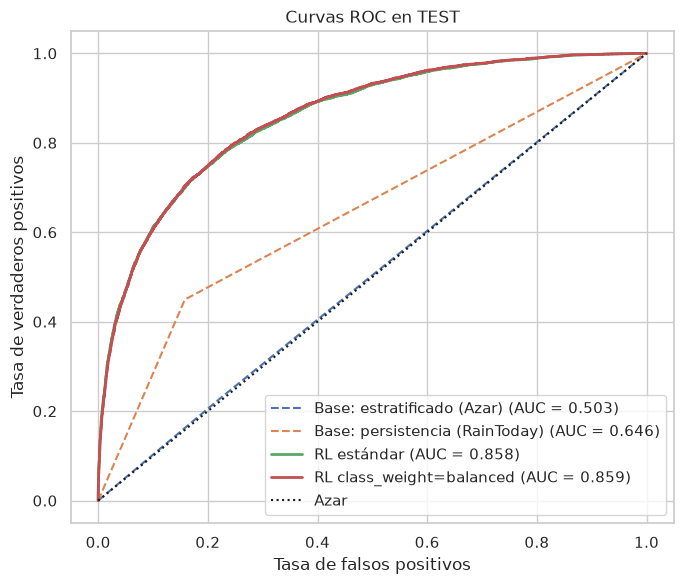

In [35]:
fig, ax = plt.subplots(figsize=(7, 6))
for n, (p, s) in baselines_test.items():
    if n == "Base: siempre 'No llueve'":
        continue   # score constante: la ROC es la diagonal
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, "--", label=f"{n} (AUC = {roc_auc_score(y_test, s):.3f})")
for n in modelos:
    fpr, tpr, _ = roc_curve(y_test, proba_test[n])
    ax.plot(fpr, tpr, lw=2, label=f"{n} (AUC = {roc_auc_score(y_test, proba_test[n]):.3f})")
ax.plot([0, 1], [0, 1], "k:", label="Azar")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Curvas ROC en TEST"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### Conclusiones

* El baseline **"siempre No llueve"** logra una accuracy de ≈ 78 % pero con **recall = 0**: no detecta ningún día de lluvia. Es la prueba de que **accuracy no sirve** con este desbalance.
* La regla de **persistencia** (`RainToday`) es un baseline más exigente, pero queda claramente por debajo de la regresión logística en F1, MCC y AUC.
* La **regresión logística supera a todos los baselines** en las métricas relevantes (F1, balanced accuracy, MCC, ROC-AUC, PR-AUC).
* **Ajustar el umbral** (en lugar de usar 0.5) mejora sensiblemente el recall y el F1 del modelo estándar, con una pequeña pérdida de accuracy.
* **Limitaciones y posibles mejoras:** modelo lineal (no captura interacciones), división aleatoria en lugar de temporal, no se usan rezagos de días previos ni información espacial entre estaciones; se podrían probar modelos no lineales (árboles, Random Forest, Gradient Boosting) y técnicas de balanceo como SMOTE.

Optimización de hiperparametros


In [36]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_squared_error
import joblib
import optuna

In [49]:
# random search
random_params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [2,3,4]
}

random_search = RandomizedSearchCV(RandomForestRegressor(random_state=42), random_params, n_iter=4, cv=2, scoring='neg_mean_squared_error', n_jobs=-1)
random_search.fit(X_train, y_train)
best_random_params = random_search.best_params_
best_random_model = lr_bal(**best_random_params, random_state=42)
best_random_model.fit(X_train, y_train)
random_search_mse = mean_squared_error(y_test, best_random_model.predict(X_test))

TypeError: 'LogisticRegression' object is not callable

In [42]:
random_search_results = pd.DataFrame(random_search.cv_results_).sort_values(by='mean_test_score', ascending=False)

In [43]:
random_search_results[['params', 'mean_test_score', 'rank_test_score']].head(10)


,params,mean_test_score,rank_test_score
0,"{'n_estimators': 100, 'min_samples_split': 2, ...",-0.1057,1
3,"{'n_estimators': 100, 'min_samples_split': 10,...",-0.1057,2
2,"{'n_estimators': 200, 'min_samples_split': 10,...",-0.1065,3
1,"{'n_estimators': 100, 'min_samples_split': 2, ...",-0.1066,4


In [48]:
# función para entrenar y evaluar un modelo con hiperparámetros dados
def train_evaluate_model(params, X_train, y_train, X_test, y_test):
    model = lr_bal(**params, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    return mse

In [47]:
def objective(trial):
    n_estimators = trial.suggest_int('n_estimators', 100, 200)
    max_depth = trial.suggest_int('max_depth', 5, 20)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 4)

    params = {
        'n_estimators': n_estimators,
        'max_depth': max_depth,
        'min_samples_split': min_samples_split,
        'min_samples_leaf': min_samples_leaf
    }

    mse = train_evaluate_model(params, X_train, y_train, X_test, y_test)
    return mse

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=10)
best_optuna_params = study.best_params
best_optuna_model = RandomForestRegressor(**best_optuna_params, random_state=42)
best_optuna_model.fit(X_train, y_train)
optuna_mse = mean_squared_error(y_test, best_optuna_model.predict(X_test))

[I 2026-10-26 20:29:37,757] A new study created in memory with name: no-name-b16a4421-e61c-4ef0-b389-91c2b777e642
[I 2026-10-26 20:33:00,156] Trial 0 finished with value: 0.10790427425930885 and parameters: {'n_estimators': 177, 'max_depth': 15, 'min_samples_split': 6, 'min_samples_leaf': 4}. Best is trial 0 with value: 0.10790427425930885.
[I 2026-10-26 20:35:00,014] Trial 1 finished with value: 0.10884728252578892 and parameters: {'n_estimators': 121, 'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 1}. Best is trial 0 with value: 0.10790427425930885.
[I 2026-10-26 20:37:10,780] Trial 2 finished with value: 0.10810425432068618 and parameters: {'n_estimators': 109, 'max_depth': 15, 'min_samples_split': 4, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.10790427425930885.
[I 2026-10-26 20:38:35,096] Trial 3 finished with value: 0.11622010987317173 and parameters: {'n_estimators': 170, 'max_depth': 6, 'min_samples_split': 5, 'min_samples_leaf': 4}. Best is trial 0 with

KeyboardInterrupt: 